# 03 — Results comparison (RQ1–RQ4)

Reads what the experiment scripts logged and puts the answers to RQ1–RQ4 side by side.
Nothing is retrained here; the only new computation is from saved test predictions
(PR curves and calibration in section 4).

| Section | Research question | Written by |
|---|---|---|
| 1–4 | **RQ1** Which model family predicts purchase best from the first K events? | `03_run_experiments.py` |
| 5 | **RQ2** How early can we predict — does performance rise with K? | `03_run_experiments.py` |
| 6 | **RQ3** What does each feature group add? | `04_run_ablation.py` |
| 7 | **RQ4** Is it fast enough for real time, and at what cost? | `05_benchmark_latency.py` |
| 8 | Hypothesis scoreboard (H1a–H4) | all of the above |

**Statistics.** Model comparisons use the primary seed's test predictions: paired
bootstrap on PR-AUC (and McNemar on labels), Holm-corrected within the confirmatory
family. Mean ± std over seeds shows training variability. PR-AUC = average precision;
*lift* = PR-AUC ÷ base rate (comparable across K).

**Run order.** Scripts 01–05 first, then `NB_MODE=dev jupyter lab`. Sections whose
results are missing are skipped with the command to run. Figures go to
`results/figures/res_*_<mode>.png`, the scoreboard to `results/tables/hypothesis_scoreboard_<mode>.csv`.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "config" / "config.yaml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
for p in (ROOT, ROOT / "scripts"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, precision_recall_curve

from _experiment import latest_runs, primary_predictions, primary_run
from src.config import resolve_path
from src.utils.notebook import (INK_MUTED, PALETTE, load_result, model_colours, notebook_config,
                                save_figure, use_style)

cfg = notebook_config()
use_style()
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_width_chars(160)
pl.Config.set_fmt_str_lengths(60)

MODE = cfg["data"]["mode"]
K0 = cfg["sessionize"]["default_k"]
ALPHA = cfg["evaluation"]["alpha"]
COLOURS = model_colours(cfg)

cmp = load_result(cfg, "rq1_model_comparison", "03_run_experiments.py")
pairs = load_result(cfg, "rq1_pairwise_tests", "03_run_experiments.py")
by_k = load_result(cfg, "rq2_by_k", "03_run_experiments.py")
hyp12 = load_result(cfg, "rq1_rq2_hypotheses", "03_run_experiments.py")
abl = load_result(cfg, "rq3_ablation", "04_run_ablation.py")
steps = load_result(cfg, "rq3_step_tests", "04_run_ablation.py")
hyp3 = load_result(cfg, "rq3_hypothesis", "04_run_ablation.py")
eff = load_result(cfg, "rq4_efficiency", "05_benchmark_latency.py")
hyp4 = load_result(cfg, "rq4_hypothesis", "05_benchmark_latency.py")
hardware = load_result(cfg, "rq4_hardware", "05_benchmark_latency.py")

MODELS = [m for m in cfg["models"]["enabled"] if cmp is not None and m in cmp["model"].to_list()]
KS = sorted(cmp["k"].unique().to_list()) if cmp is not None else []
if KS and K0 not in KS:
    K0 = KS[len(KS) // 2]


def ordered(df: pl.DataFrame, col: str = "model") -> pl.DataFrame:
    rank = {m: i for i, m in enumerate(cfg["models"]["enabled"])}
    return df.with_columns(_o=pl.col(col).replace_strict(rank, default=99)).sort("_o").drop("_o")


def pm(mean: str, std: str, digits: int = 3) -> pl.Expr:
    fmt = f"{{:.{digits}f}}"
    return pl.format("{} ± {}", pl.col(mean).map_elements(fmt.format, return_dtype=pl.String),
                     pl.col(std).fill_null(0).map_elements(fmt.format, return_dtype=pl.String))


print(f"mode={MODE}  K={KS}  default K={K0}  models={MODELS}  alpha={ALPHA}")

mode=full  K=[3, 5, 10]  default K=5  models=['rule_based', 'logistic_regression', 'random_forest', 'lightgbm', 'mlp', 'tabnet', 'gru']  alpha=0.05


### Run inventory

In [2]:
from src.utils.results_logger import load_runs

runs = load_runs(cfg)
if runs.height:
    display(runs.filter(pl.col("data_mode") == MODE)
            .group_by("experiment").agg(runs=pl.len(), models=pl.col("model").n_unique(),
                                        seeds=pl.col("seed").n_unique(), k=pl.col("k").unique().sort())
            .sort("experiment"))
else:
    print("No runs logged yet.")

experiment,runs,models,seeds,k
str,u32,u32,u32,list[i64]
"""rq1_models""",78,7,3,"[3, 5, 10]"
"""rq3_ablation""",144,2,3,"[3, 5, 10]"
"""rq4_efficiency""",42,7,1,"[3, 5, 10]"
"""rq5_explain""",30,5,1,"[3, 5, 10]"


## 1. RQ1 — Model comparison

Test-set metrics, mean ± std over seeds. Precision / recall / F1 are at the threshold
tuned for F1 on validation. The CI is the 95% bootstrap interval of the primary seed's PR-AUC.

In [3]:
if cmp is not None:
    rq1_table = ordered(cmp).select(
        "k", "model", "n_seeds",
        pm("pr_auc_mean", "pr_auc_std").alias("PR-AUC"),
        pl.format("[{}, {}]", pl.col("pr_auc_ci_low").round(3), pl.col("pr_auc_ci_high").round(3)).alias("95% CI (primary)"),
        pl.col("pr_auc_lift_mean").round(2).alias("lift"),
        pm("roc_auc_mean", "roc_auc_std").alias("ROC-AUC"),
        pm("f1_mean", "f1_std").alias("F1"),
        pl.col("precision_mean").round(3).alias("precision"),
        pl.col("recall_mean").round(3).alias("recall"),
        pl.col("base_rate").round(4).alias("base rate"),
    ).sort("k", maintain_order=True)
    for k in KS:
        print(f"K = {k}")
        display(rq1_table.filter(pl.col("k") == k).drop("k"))

K = 3


model,n_seeds,PR-AUC,95% CI (primary),lift,ROC-AUC,F1,precision,recall,base rate
str,i64,str,str,f64,str,str,f64,f64,f64
"""rule_based""",1,"""0.246 ± 0.000""","""[0.243, 0.249]""",2.32,"""0.686 ± 0.000""","""0.432 ± 0.000""",0.421,0.444,0.1061
"""logistic_regression""",3,"""0.340 ± 0.000""","""[0.335, 0.345]""",3.21,"""0.752 ± 0.000""","""0.432 ± 0.000""",0.423,0.443,0.1061
"""random_forest""",3,"""0.356 ± 0.000""","""[0.351, 0.36]""",3.35,"""0.760 ± 0.000""","""0.433 ± 0.000""",0.425,0.441,0.1061
"""lightgbm""",3,"""0.353 ± 0.000""","""[0.348, 0.358]""",3.33,"""0.758 ± 0.000""","""0.432 ± 0.000""",0.424,0.44,0.1061
"""mlp""",3,"""0.353 ± 0.000""","""[0.349, 0.358]""",3.33,"""0.758 ± 0.001""","""0.433 ± 0.000""",0.423,0.443,0.1061
"""tabnet""",3,"""0.346 ± 0.005""","""[0.344, 0.353]""",3.27,"""0.754 ± 0.002""","""0.432 ± 0.001""",0.424,0.44,0.1061
"""gru""",3,"""0.353 ± 0.002""","""[0.35, 0.359]""",3.33,"""0.751 ± 0.002""","""0.432 ± 0.000""",0.427,0.437,0.1061


K = 5


model,n_seeds,PR-AUC,95% CI (primary),lift,ROC-AUC,F1,precision,recall,base rate
str,i64,str,str,f64,str,str,f64,f64,f64
"""rule_based""",1,"""0.214 ± 0.000""","""[0.211, 0.218]""",2.11,"""0.679 ± 0.000""","""0.395 ± 0.000""",0.351,0.452,0.1016
"""logistic_regression""",3,"""0.325 ± 0.000""","""[0.32, 0.331]""",3.2,"""0.759 ± 0.000""","""0.401 ± 0.000""",0.377,0.428,0.1016
"""random_forest""",3,"""0.337 ± 0.000""","""[0.332, 0.343]""",3.31,"""0.762 ± 0.000""","""0.400 ± 0.000""",0.39,0.411,0.1016
"""lightgbm""",3,"""0.333 ± 0.000""","""[0.327, 0.339]""",3.28,"""0.761 ± 0.000""","""0.399 ± 0.001""",0.388,0.411,0.1016
"""mlp""",3,"""0.333 ± 0.000""","""[0.327, 0.339]""",3.27,"""0.761 ± 0.000""","""0.399 ± 0.000""",0.381,0.419,0.1016
"""tabnet""",3,"""0.326 ± 0.002""","""[0.319, 0.33]""",3.21,"""0.758 ± 0.004""","""0.395 ± 0.004""",0.368,0.426,0.1016
"""gru""",3,"""0.336 ± 0.001""","""[0.33, 0.341]""",3.3,"""0.756 ± 0.001""","""0.401 ± 0.001""",0.391,0.412,0.1016


K = 10


model,n_seeds,PR-AUC,95% CI (primary),lift,ROC-AUC,F1,precision,recall,base rate
str,i64,str,str,f64,str,str,f64,f64,f64
"""rule_based""",1,"""0.176 ± 0.000""","""[0.172, 0.18]""",1.8,"""0.655 ± 0.000""","""0.339 ± 0.000""",0.28,0.43,0.0977
"""logistic_regression""",3,"""0.291 ± 0.000""","""[0.284, 0.299]""",2.98,"""0.753 ± 0.000""","""0.357 ± 0.000""",0.335,0.382,0.0977
"""random_forest""",3,"""0.296 ± 0.000""","""[0.289, 0.304]""",3.03,"""0.755 ± 0.000""","""0.358 ± 0.001""",0.337,0.383,0.0977
"""lightgbm""",3,"""0.292 ± 0.002""","""[0.286, 0.302]""",2.99,"""0.755 ± 0.000""","""0.356 ± 0.000""",0.337,0.378,0.0977
"""mlp""",3,"""0.291 ± 0.000""","""[0.283, 0.298]""",2.98,"""0.754 ± 0.001""","""0.355 ± 0.000""",0.344,0.367,0.0977
"""tabnet""",3,"""0.288 ± 0.003""","""[0.284, 0.299]""",2.95,"""0.750 ± 0.003""","""0.349 ± 0.003""",0.329,0.372,0.0977
"""gru""",3,"""0.296 ± 0.000""","""[0.288, 0.303]""",3.03,"""0.750 ± 0.001""","""0.355 ± 0.000""",0.355,0.356,0.0977


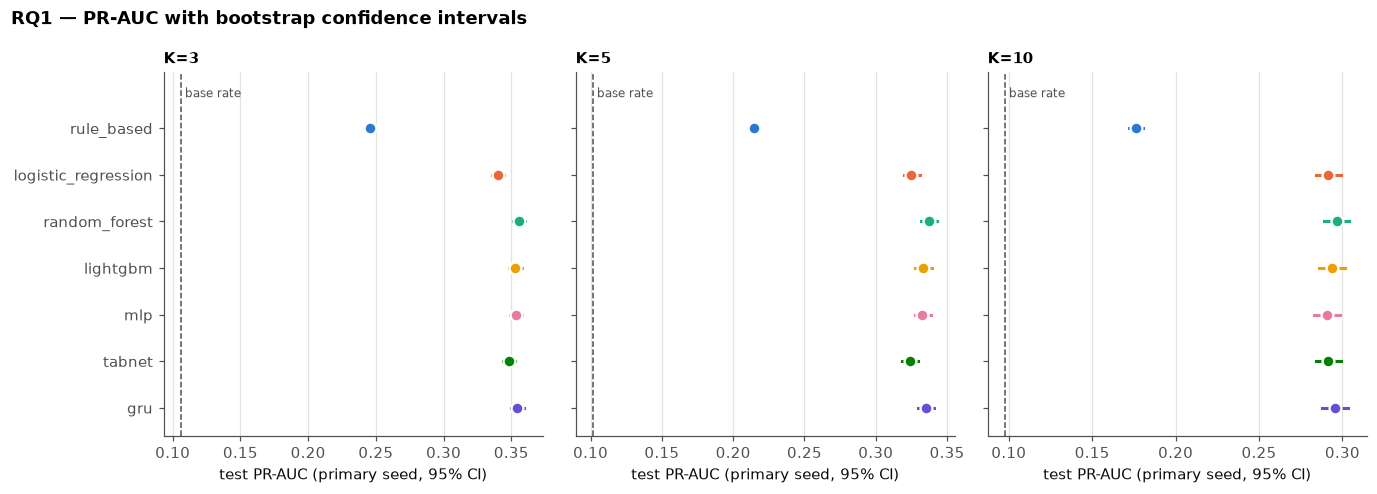

In [4]:
if cmp is not None:
    fig, axes = plt.subplots(1, len(KS), figsize=(4.2 * len(KS), 0.42 * len(MODELS) + 1.6), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, k in zip(axes, KS):
        d = ordered(cmp.filter(pl.col("k") == k))
        y = np.arange(d.height)[::-1]
        for yi, r in zip(y, d.iter_rows(named=True)):
            ax.plot([r["pr_auc_ci_low"], r["pr_auc_ci_high"]], [yi, yi], color=COLOURS[r["model"]], linewidth=2)
            ax.scatter(r["pr_auc_primary"], yi, s=60, color=COLOURS[r["model"]], edgecolor="white", linewidth=1.5, zorder=3)
        ax.axvline(d["base_rate"][0], color=INK_MUTED, linestyle="--", linewidth=1)
        ax.text(d["base_rate"][0], y.max() + 0.6, " base rate", fontsize=8, color=INK_MUTED, va="bottom")
        ax.set_yticks(y, d["model"])
        ax.set_title(f"K={k}", fontsize=10)
        ax.set_xlabel("test PR-AUC (primary seed, 95% CI)")
        ax.grid(axis="y", visible=False)
        ax.set_ylim(-0.6, y.max() + 1.2)
    fig.suptitle("RQ1 — PR-AUC with bootstrap confidence intervals", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    save_figure(fig, cfg, "res_rq1_pr_auc_ci")
    plt.show()

## 2. RQ1 — At the operating threshold

What the tuned threshold means in practice at the default K: how many flagged sessions
really buy (precision), how many buyers are caught (recall), and the confusion counts
of the primary-seed model.

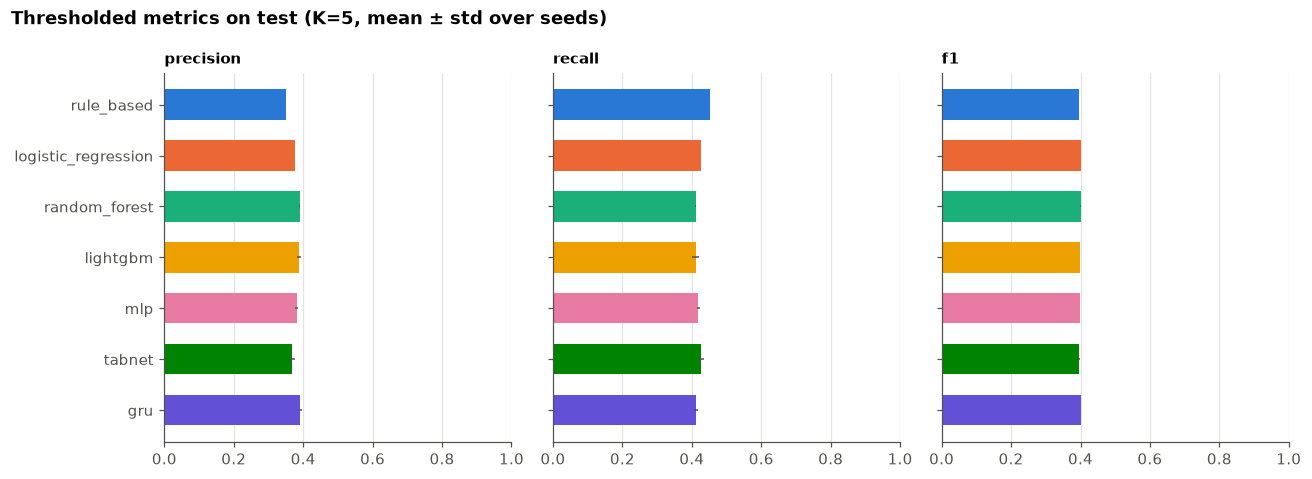

model,threshold,test_tp,test_fp,test_fn,test_tn,flagged_share
str,f64,f64,f64,f64,f64,f64
"""rule_based""",0.5,13592.0,25129.0,16454.0,240470.0,0.131
"""logistic_regression""",0.69,12847.0,21197.0,17199.0,244402.0,0.115
"""random_forest""",0.699,12279.0,19112.0,17767.0,246487.0,0.106
"""lightgbm""",0.717,12147.0,18728.0,17899.0,246871.0,0.104
"""mlp""",0.69,12588.0,20442.0,17458.0,245157.0,0.112
"""tabnet""",0.715,12577.0,21341.0,17469.0,244258.0,0.115
"""gru""",0.69,12540.0,19815.0,17506.0,245784.0,0.109


In [5]:
if cmp is not None:
    d = ordered(cmp.filter(pl.col("k") == K0))
    fig, axes = plt.subplots(1, 3, figsize=(12, 0.4 * d.height + 1.6), sharey=True)
    y = np.arange(d.height)[::-1]
    for ax, metric in zip(axes, ("precision", "recall", "f1")):
        ax.barh(y, d[f"{metric}_mean"], xerr=d[f"{metric}_std"].fill_null(0), height=0.6,
                color=[COLOURS[m] for m in d["model"]], error_kw={"ecolor": INK_MUTED, "elinewidth": 1})
        ax.set_title(metric, fontsize=10)
        ax.set_xlim(0, 1)
        ax.grid(axis="y", visible=False)
    axes[0].set_yticks(y, d["model"])
    fig.suptitle(f"Thresholded metrics on test (K={K0}, mean ± std over seeds)", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    save_figure(fig, cfg, "res_rq1_threshold_metrics")
    plt.show()

    rq1_runs = latest_runs(cfg, "rq1_models")
    conf = pl.concat([primary_run(cfg, rq1_runs.filter((pl.col("k") == K0) & (pl.col("model") == m)))
                      for m in MODELS]).select(
        "model", pl.col("threshold").round(3), "test_tp", "test_fp", "test_fn", "test_tn",
        pl.col("test_predicted_positive_rate").round(3).alias("flagged_share"))
    display(ordered(conf))

## 3. RQ1 — Pairwise significance

Cell = PR-AUC of the **row** model minus the **column** model at the default K (primary
seed). `*` = significant after Holm correction within its family (bootstrap p < α).
The confirmatory family holds the comparisons the hypotheses make; its table follows.

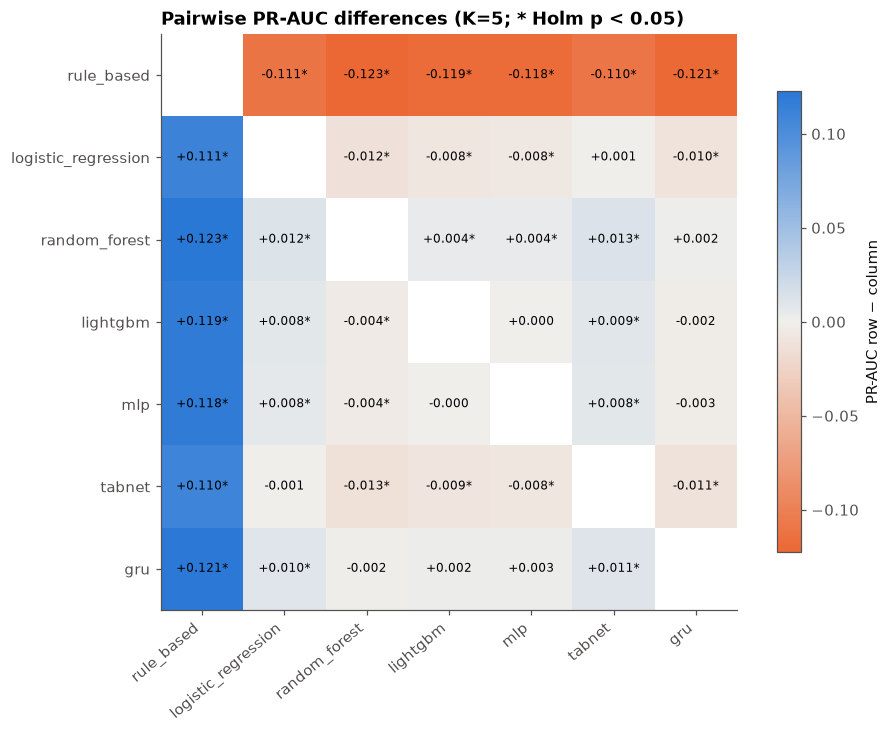

k,model_a,model_b,pr_auc_diff,95% CI,p_bootstrap_holm,p_mcnemar_holm,significant
i64,str,str,f64,str,f64,f64,bool
3,"""logistic_regression""","""lightgbm""",-0.0128,"""[-0.0153, -0.0105]""",0.0,0.0,true
3,"""logistic_regression""","""mlp""",-0.0132,"""[-0.0156, -0.0108]""",0.0,0.0001,true
3,"""logistic_regression""","""random_forest""",-0.0154,"""[-0.0181, -0.0128]""",0.0,0.0,true
3,"""logistic_regression""","""tabnet""",-0.0082,"""[-0.0106, -0.006]""",0.0,0.0,true
5,"""logistic_regression""","""lightgbm""",-0.008,"""[-0.0105, -0.0056]""",0.0,0.0,true
5,"""logistic_regression""","""mlp""",-0.0077,"""[-0.0104, -0.005]""",0.0,0.0,true
5,"""logistic_regression""","""random_forest""",-0.012,"""[-0.0149, -0.0092]""",0.0,0.0,true
5,"""logistic_regression""","""tabnet""",0.0008,"""[-0.0022, 0.0038]""",1.0,0.0,false
10,"""logistic_regression""","""lightgbm""",-0.0025,"""[-0.0059, 0.0008]""",0.61,0.0,false


In [6]:
if pairs is not None:
    d = pairs.filter(pl.col("k") == K0)
    n = len(MODELS)
    idx = {m: i for i, m in enumerate(MODELS)}
    diff = np.full((n, n), np.nan)
    sig = np.zeros((n, n), dtype=bool)
    for r in d.iter_rows(named=True):
        if r["model_a"] in idx and r["model_b"] in idx:
            i, j = idx[r["model_a"]], idx[r["model_b"]]
            diff[i, j], diff[j, i] = r["pr_auc_diff"], -r["pr_auc_diff"]
            sig[i, j] = sig[j, i] = r["p_bootstrap_holm"] < ALPHA
    lim = np.nanmax(np.abs(diff)) if np.isfinite(diff).any() else 1
    cmap = LinearSegmentedColormap.from_list("div", [PALETTE[1], "#f0efec", PALETTE[0]])
    fig, ax = plt.subplots(figsize=(1.0 * n + 2.5, 0.8 * n + 1.2))
    im = ax.imshow(diff, cmap=cmap, vmin=-lim, vmax=lim)
    for i in range(n):
        for j in range(n):
            if i != j and np.isfinite(diff[i, j]):
                ax.text(j, i, f"{diff[i, j]:+.3f}{'*' if sig[i, j] else ''}", ha="center", va="center", fontsize=8)
    ax.set_xticks(range(n), MODELS, rotation=40, ha="right")
    ax.set_yticks(range(n), MODELS)
    ax.grid(False)
    fig.colorbar(im, ax=ax, shrink=0.8, label="PR-AUC row − column")
    ax.set_title(f"Pairwise PR-AUC differences (K={K0}; * Holm p < {ALPHA})")
    save_figure(fig, cfg, "res_rq1_pairwise")
    plt.show()

    confirm = pairs.filter(pl.col("family") == "confirmatory").select(
        "k", "model_a", "model_b", pl.col("pr_auc_diff").round(4),
        pl.format("[{}, {}]", pl.col("diff_ci_low").round(4), pl.col("diff_ci_high").round(4)).alias("95% CI"),
        pl.col("p_bootstrap_holm").round(4), pl.col("p_mcnemar_holm").round(4),
        (pl.col("p_bootstrap_holm") < ALPHA).alias("significant"),
    ).sort("k", "model_a")
    display(confirm)

**Seed stability.** Standard deviation of test PR-AUC across seeds (0 for the
deterministic rule). A model whose spread is as large as its gap to a rival cannot be
called better on one seed alone.

In [7]:
if cmp is not None:
    display(ordered(cmp.pivot(on="k", index="model", values="pr_auc_std", sort_columns=True)))

model,3,5,10
str,f64,f64,f64
"""rule_based""",0.0,0.0,0.0
"""logistic_regression""",0.0,0.0,0.0
"""random_forest""",0.000054,0.00016,0.000351
"""lightgbm""",0.000041,0.000187,0.00196
"""mlp""",0.000137,0.000145,0.000273
"""tabnet""",0.005224,0.002298,0.003078
"""gru""",0.001635,0.000551,0.000247


## 4. RQ1 — PR curves and calibration

From the primary seed's saved test predictions at the default K. Calibration matters if
scores are used as probabilities (e.g. "70% likely to buy"): class weighting and
oversampling push scores up, so a model can rank well (high PR-AUC) yet be poorly
calibrated. Brier score: lower is better.

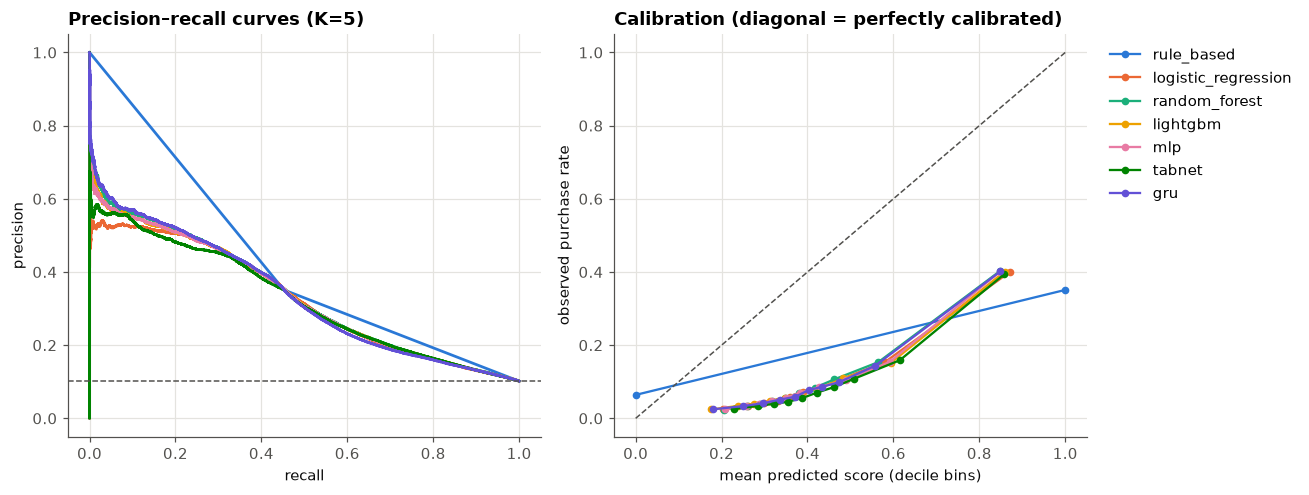

model,brier,mean_score,base_rate
str,f64,f64,f64
"""rule_based""",0.1407,0.131,0.1016
"""logistic_regression""",0.1872,0.419,0.1016
"""random_forest""",0.1797,0.409,0.1016
"""lightgbm""",0.1833,0.4102,0.1016
"""mlp""",0.1849,0.4157,0.1016
"""tabnet""",0.2035,0.4443,0.1016
"""gru""",0.1845,0.4149,0.1016


In [8]:
if cmp is not None:
    rq1_runs = latest_runs(cfg, "rq1_models")
    preds = {m: primary_predictions(cfg, rq1_runs.filter((pl.col("k") == K0) & (pl.col("model") == m)))
             for m in MODELS}
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
    brier = []
    for m, p in preds.items():
        y, s = p["y_true"].to_numpy(), p["score"].to_numpy()
        if y.min() == y.max():
            continue
        prec, rec, _ = precision_recall_curve(y, s)
        axes[0].plot(rec, prec, color=COLOURS[m], label=m, linewidth=1.8)
        s01 = np.clip(s, 0, 1)
        frac_pos, mean_pred = calibration_curve(y, s01, n_bins=10, strategy="quantile")
        axes[1].plot(mean_pred, frac_pos, marker="o", markersize=4, color=COLOURS[m], label=m, linewidth=1.5)
        brier.append({"model": m, "brier": brier_score_loss(y, s01), "mean_score": float(s01.mean()), "base_rate": float(y.mean())})
    base = next(iter(preds.values()))["y_true"].mean()
    axes[0].axhline(base, color=INK_MUTED, linestyle="--", linewidth=1)
    axes[0].set_xlabel("recall")
    axes[0].set_ylabel("precision")
    axes[0].set_title(f"Precision–recall curves (K={K0})")
    axes[1].plot([0, 1], [0, 1], color=INK_MUTED, linestyle="--", linewidth=1)
    axes[1].set_xlabel("mean predicted score (decile bins)")
    axes[1].set_ylabel("observed purchase rate")
    axes[1].set_title("Calibration (diagonal = perfectly calibrated)")
    axes[1].legend(loc="upper left", bbox_to_anchor=(1.02, 1))
    fig.tight_layout()
    save_figure(fig, cfg, "res_rq1_curves_calibration")
    plt.show()
    display(ordered(pl.DataFrame(brier)).with_columns(pl.col(pl.Float64).round(4)))

## 5. RQ2 — How early can we predict?

Raw PR-AUC partly tracks the base rate, which differs by K, so read the **lift** and
**ROC-AUC** panels for the effect of K. H2 expects a rise with diminishing returns.

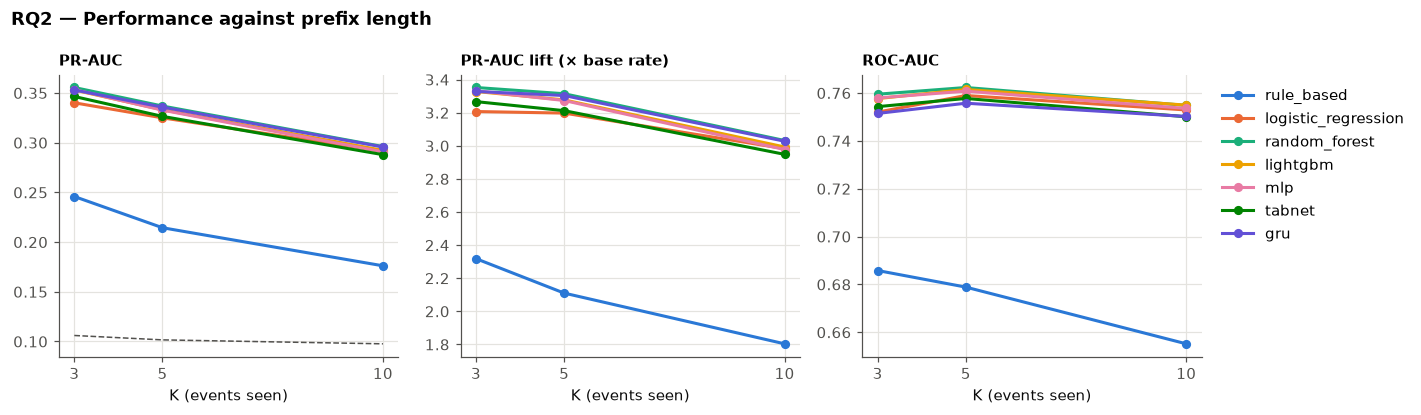

H2: not supported — rising for 0/7 models, diminishing for 0/7 (measure: PR-AUC lift over the base rate (base rate differs by K))


model,lift K=3,lift K=5,lift K=10,rising,diminishing
str,f64,f64,f64,bool,bool
"""lightgbm""",3.328,3.278,2.993,false,false
"""gru""",3.329,3.304,3.028,false,false
"""tabnet""",3.267,3.212,2.949,false,false
"""rule_based""",2.318,2.11,1.804,false,false
"""random_forest""",3.352,3.315,3.032,false,false
"""mlp""",3.333,3.274,2.978,false,false
"""logistic_regression""",3.207,3.198,2.983,false,false


In [9]:
if by_k is not None:
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
    for ax, (col, label) in zip(axes, [("pr_auc_mean", "PR-AUC"), ("pr_auc_lift_mean", "PR-AUC lift (× base rate)"),
                                       ("roc_auc_mean", "ROC-AUC")]):
        for m in MODELS:
            d = by_k.filter(pl.col("model") == m).sort("k")
            ax.plot(d["k"], d[col], marker="o", markersize=5, color=COLOURS[m], label=m)
        if col == "pr_auc_mean":
            b = by_k.group_by("k").agg(pl.col("base_rate").first()).sort("k")
            ax.plot(b["k"], b["base_rate"], color=INK_MUTED, linestyle="--", linewidth=1, label="base rate")
        ax.set_xticks(KS)
        ax.set_xlabel("K (events seen)")
        ax.set_title(label, fontsize=10)
    axes[-1].legend(loc="upper left", bbox_to_anchor=(1.02, 1))
    fig.suptitle("RQ2 — Performance against prefix length", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    save_figure(fig, cfg, "res_rq2_vs_k")
    plt.show()
if hyp12 is not None:
    h2 = hyp12["H2_performance_rises_with_k_diminishing"]
    print(f"H2: {h2['verdict']} — rising for {h2['models_rising']} models, diminishing for {h2['models_diminishing']} "
          f"(measure: {h2['measure']})")
    display(pl.DataFrame([{"model": e["model"], **{f"lift K={k}": round(v, 3) for k, v in e["lift_by_k"].items()},
                           "rising": e["rising"], "diminishing": e["diminishing"]} for e in h2["evidence"]]))

## 6. RQ3 — Feature-group ablation

Cumulative ladder S1 → S5 (G1 activity, + G2 cart signals, + G3 ratios, + G4 categories,
+ G5 price & time) for the ablation models, plus the exploratory variant (G1 + G3, hollow
marker) that tests whether the ratios can *replace* the cart block.

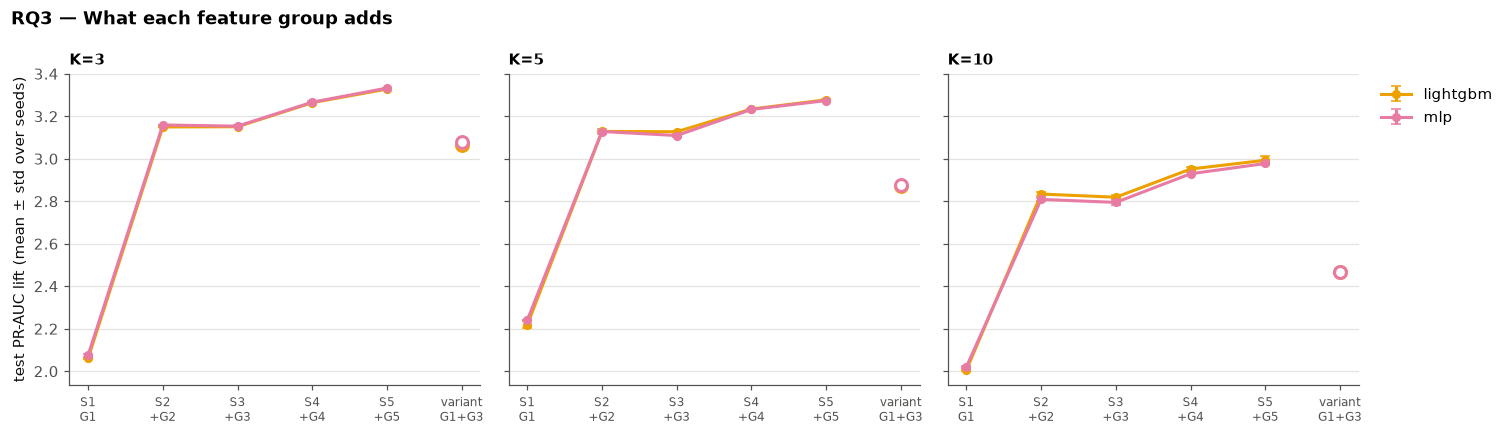

In [10]:
if abl is not None:
    ab_models = [m for m in cfg["models"]["enabled"] if m in abl["model"].to_list()]
    ab_ks = sorted(abl["k"].unique().to_list())
    fig, axes = plt.subplots(1, len(ab_ks), figsize=(4.6 * len(ab_ks), 4), sharey=True)
    axes = np.atleast_1d(axes)
    ladder_labels = None
    for ax, k in zip(axes, ab_ks):
        for m in ab_models:
            d = abl.filter((pl.col("k") == k) & (pl.col("model") == m))
            lad = d.filter(~pl.col("is_variant")).sort("step")
            ax.errorbar(lad["step"], lad["pr_auc_lift_mean"],
                        yerr=(lad["pr_auc_std"].fill_null(0) / lad["base_rate"]), color=COLOURS[m],
                        marker="o", markersize=5, capsize=3, label=m)
            for r in d.filter(pl.col("is_variant")).iter_rows(named=True):
                x = lad["step"].max() + 1
                ax.scatter(x, r["pr_auc_lift_mean"], s=60, facecolor="white", edgecolor=COLOURS[m], linewidth=2, zorder=3)
            ladder_labels = [s.split(":")[0] + "\n" + ("" if i == 0 else "+") + s.split(":")[1].split("+")[-1]
                             for i, s in enumerate(lad["feature_set"])]
        xt = list(range(1, len(ladder_labels) + 1))
        if abl["is_variant"].any():
            xt.append(len(ladder_labels) + 1)
            ladder_labels = ladder_labels + ["variant\nG1+G3"]
        ax.set_xticks(xt, ladder_labels, fontsize=8)
        ax.set_title(f"K={k}", fontsize=10)
        ax.grid(axis="x", visible=False)
    axes[0].set_ylabel("test PR-AUC lift (mean ± std over seeds)")
    axes[-1].legend(loc="upper left", bbox_to_anchor=(1.02, 1))
    fig.suptitle("RQ3 — What each feature group adds", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    save_figure(fig, cfg, "res_rq3_ladder")
    plt.show()

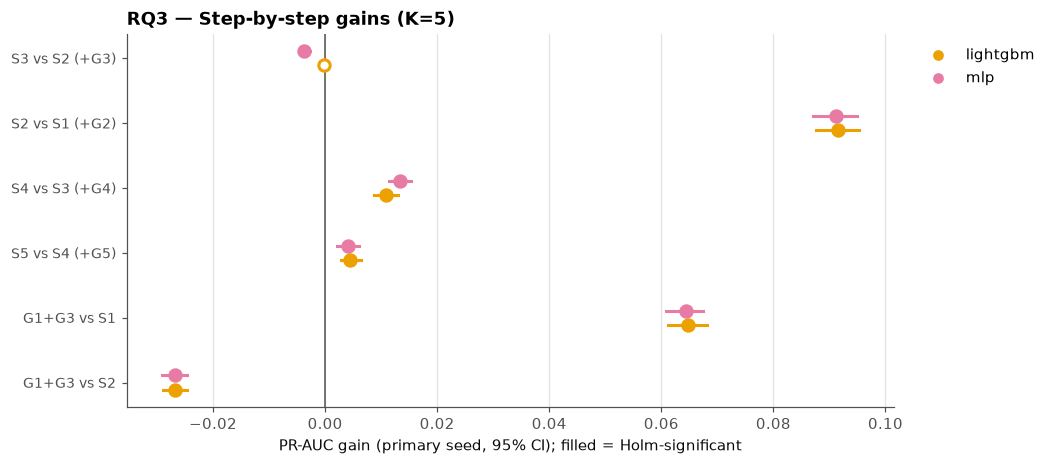

k,model,family,from,to,pr_auc_gain,gain_ci_low,gain_ci_high,p_bootstrap_holm
i64,str,str,str,str,f64,f64,f64,f64
3,"""lightgbm""","""confirmatory""","""S2:G1+G2""","""S3:G1+G2+G3""",0.0,-0.0002,0.0002,1.0
3,"""mlp""","""confirmatory""","""S2:G1+G2""","""S3:G1+G2+G3""",-0.0002,-0.0006,0.0001,0.618
5,"""lightgbm""","""confirmatory""","""S2:G1+G2""","""S3:G1+G2+G3""",-0.0001,-0.0006,0.0003,1.0
5,"""mlp""","""confirmatory""","""S2:G1+G2""","""S3:G1+G2+G3""",-0.0037,-0.0047,-0.0027,0.0
10,"""lightgbm""","""confirmatory""","""S2:G1+G2""","""S3:G1+G2+G3""",-0.0017,-0.0029,-0.0005,0.01
10,"""mlp""","""confirmatory""","""S2:G1+G2""","""S3:G1+G2+G3""",-0.0012,-0.0022,-0.0001,0.136
3,"""lightgbm""","""exploratory""","""S3:G1+G2+G3""","""S4:G1+G2+G3+G4""",0.0119,0.0102,0.0137,0.0
3,"""lightgbm""","""exploratory""","""S4:G1+G2+G3+G4""","""S5:G1+G2+G3+G4+G5""",0.0069,0.0055,0.0081,0.0
3,"""lightgbm""","""exploratory""","""S1:G1""","""S2:G1+G2""",0.1157,0.112,0.1191,0.0


H3: not supported — significant gains in 0/6 (ladder step adding G3 vs the step before it; paired bootstrap on test PR-AUC, Holm-adjusted over the confirmatory family)
Variant: Can G1+G3 replace G1+G2? (variant vs ladder step 2) -> variant significantly worse in 6/6 comparisons


In [11]:
if steps is not None:
    def step_label(r):
        frm, to = r["from"].split(":")[0], r["to"].split(":")[0]
        return f"{to} vs {frm} (+{r['added']})" if r["family"] != "variant" else f"G1+G3 vs {frm}"

    d = steps.filter(pl.col("k") == K0).with_columns(
        label=pl.struct("from", "to", "added", "family").map_elements(step_label, return_dtype=pl.String))
    ab_models = [m for m in cfg["models"]["enabled"] if m in d["model"].to_list()]
    labels = list(dict.fromkeys(d.sort("family", "step")["label"].to_list()))
    fig, ax = plt.subplots(figsize=(9, 0.5 * len(labels) + 1.4))
    offset = {m: (i - (len(ab_models) - 1) / 2) * 0.22 for i, m in enumerate(ab_models)}
    for r in d.iter_rows(named=True):
        yi = len(labels) - 1 - labels.index(r["label"]) + offset[r["model"]]
        ax.plot([r["gain_ci_low"], r["gain_ci_high"]], [yi, yi], color=COLOURS[r["model"]], linewidth=2)
        sig = r["p_bootstrap_holm"] < ALPHA
        ax.scatter(r["pr_auc_gain"], yi, s=55, color=COLOURS[r["model"]] if sig else "white",
                   edgecolor=COLOURS[r["model"]], linewidth=2, zorder=3)
    ax.axvline(0, color=INK_MUTED, linewidth=1)
    ax.set_yticks(range(len(labels)), labels[::-1], fontsize=9)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("PR-AUC gain (primary seed, 95% CI); filled = Holm-significant")
    for m in ab_models:
        ax.scatter([], [], color=COLOURS[m], label=m)
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
    ax.set_title(f"RQ3 — Step-by-step gains (K={K0})")
    save_figure(fig, cfg, "res_rq3_step_gains")
    plt.show()
    display(steps.select("k", "model", "family", "from", "to", pl.col("pr_auc_gain").round(4),
                         pl.col("gain_ci_low").round(4), pl.col("gain_ci_high").round(4),
                         pl.col("p_bootstrap_holm").round(4)).sort("family", "k", "model"))
if hyp3 is not None:
    h3 = hyp3["H3_behavioural_ratios_add_pr_auc"]
    print(f"H3: {h3['verdict']} — significant gains in {h3['significant_gains']} ({h3['comparison']})")
    v = hyp3.get("exploratory_ratios_instead_of_counts")
    if v:
        print(f"Variant: {v['question']} -> {v['summary']}")

## 7. RQ4 — Real-time feasibility and cost

Single-thread CPU inference of the primary-seed models. The real-time budget
(`efficiency.realtime_budget_ms`, p95 for one session) is an assumption stated in the
report. The Pareto front joins the models no other model beats on both PR-AUC and latency.

In [12]:
if hardware is not None:
    print({k: v for k, v in hardware.items() if not isinstance(v, dict)})
if eff is not None:
    budget = float(cfg["efficiency"]["realtime_budget_ms"])
    big = max(int(c.split("_")[1][1:]) for c in eff.columns if c.startswith("throughput_b"))
    eff_table = ordered(eff).select(
        "k", "model", pl.col("test_pr_auc_mean").round(3).alias("PR-AUC"),
        pl.col("latency_b1_p50_ms").round(4).alias("p50 ms (1)"),
        pl.col("latency_b1_p95_ms").round(4).alias("p95 ms (1)"),
        pl.col("latency_b1_p99_ms").round(4).alias("p99 ms (1)"),
        pl.col(f"throughput_b{big}_per_sec").round(0).alias(f"sessions/s (batch {big})"),
        pl.col("train_time_sec_mean").round(2).alias("train s"),
        pl.col("model_size_mb").round(3).alias("size MB"),
        pl.col("infer_peak_memory_mb").round(1).alias("infer MB"),
        (pl.col("latency_b1_p95_ms") <= budget).alias("within budget"),
    ).sort("k", maintain_order=True)
    display(eff_table.filter(pl.col("k") == K0))

{'platform': 'macOS-27.0.1-arm64-arm-64bit', 'machine': 'arm64', 'processor': 'arm', 'cpu_physical': 15, 'cpu_logical': 15, 'ram_gb': 25.8, 'python': '3.12.10', 'numpy_version': '2.5.4', 'polars_version': '2.1.0', 'sklearn_version': '1.9.1', 'lightgbm_version': '4.7.0', 'torch_version': '2.15.0', 'pytorch_tabnet_version': 'unknown'}


k,model,PR-AUC,p50 ms (1),p95 ms (1),p99 ms (1),sessions/s (batch 4096),train s,size MB,infer MB,within budget
i64,str,f64,f64,f64,f64,f64,f64,f64,f64,bool
5,"""rule_based""",0.214,0.0008,0.0008,0.0009,1.6215e9,0.0,0.0,0.0,true
5,"""logistic_regression""",0.325,0.0287,0.0316,0.0332,3.7063409e7,1.35,0.002,0.1,true
5,"""random_forest""",0.337,5.1123,5.4123,5.5028,51402.0,33.6,105.128,11.9,true
5,"""lightgbm""",0.333,0.1344,0.1579,0.2466,110451.0,5.75,0.929,0.2,true
5,"""mlp""",0.333,0.0546,0.0796,0.1257,4.46045e6,54.64,0.09,38.2,true
5,"""tabnet""",0.326,0.9103,0.9437,0.9643,189791.0,326.63,0.825,640.8,true
5,"""gru""",0.336,0.0822,0.0875,0.093,466062.0,249.01,0.068,46.1,true


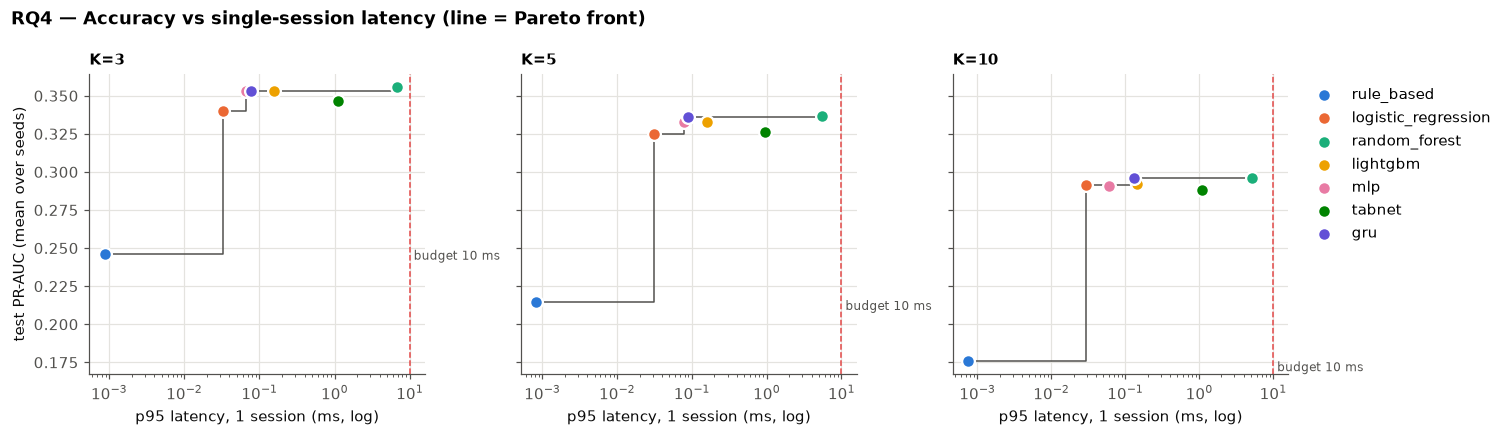

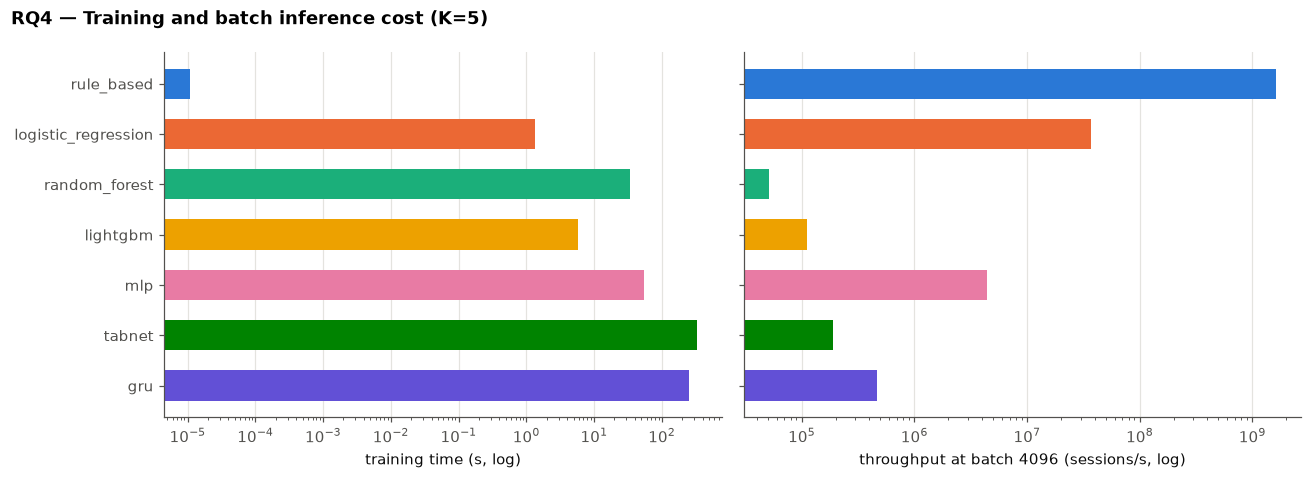

H4: not supported — trees dominate at 0/3 K values (at each K, every Pareto-optimal non-baseline model (PR-AUC vs p95 single-session latency) is a tree model)


K,over_budget,front (all),front (non-baseline),trees_dominate
i64,str,str,str,bool
3,"""—""","""rule_based, logistic_regression, random_forest, mlp""","""random_forest, mlp""",false
5,"""—""","""rule_based, logistic_regression, random_forest, mlp, gru""","""random_forest, mlp, gru""",false
10,"""—""","""rule_based, logistic_regression, random_forest, gru""","""random_forest, mlp, gru""",false


In [13]:
if eff is not None:
    eff_ks = sorted(eff["k"].unique().to_list())
    fig, axes = plt.subplots(1, len(eff_ks), figsize=(4.6 * len(eff_ks), 4), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, k in zip(axes, eff_ks):
        d = eff.filter(pl.col("k") == k)
        front = hyp4["per_k"][str(k)]["pareto_front_all_models"] if hyp4 else []
        f = d.filter(pl.col("model").is_in(front)).sort("latency_b1_p95_ms")
        ax.step(f["latency_b1_p95_ms"], f["test_pr_auc_mean"], where="post", color=INK_MUTED, linewidth=1, zorder=1)
        for r in d.iter_rows(named=True):
            ax.scatter(r["latency_b1_p95_ms"], r["test_pr_auc_mean"], s=70, color=COLOURS[r["model"]],
                       edgecolor="white", linewidth=1.5, zorder=3, label=r["model"])
        ax.axvline(budget, color=PALETTE[7], linestyle="--", linewidth=1)
        ax.text(budget, ax.get_ylim()[0], f" budget {budget:g} ms", color=INK_MUTED, fontsize=8, va="bottom")
        ax.set_xscale("log")
        ax.set_xlabel("p95 latency, 1 session (ms, log)")
        ax.set_title(f"K={k}", fontsize=10)
    axes[0].set_ylabel("test PR-AUC (mean over seeds)")
    h, l = axes[-1].get_legend_handles_labels()
    axes[-1].legend(h, l, loc="upper left", bbox_to_anchor=(1.02, 1))
    fig.suptitle("RQ4 — Accuracy vs single-session latency (line = Pareto front)", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    save_figure(fig, cfg, "res_rq4_pareto")
    plt.show()

    d = ordered(eff.filter(pl.col("k") == K0))
    fig, axes = plt.subplots(1, 2, figsize=(12, 0.4 * d.height + 1.6), sharey=True)
    y = np.arange(d.height)[::-1]
    for ax, col, label in ((axes[0], "train_time_sec_mean", "training time (s, log)"),
                           (axes[1], f"throughput_b{big}_per_sec", f"throughput at batch {big} (sessions/s, log)")):
        vals = d[col].fill_null(0).to_numpy()
        ax.barh(y, np.where(vals > 0, vals, np.nan), height=0.6, color=[COLOURS[m] for m in d["model"]])
        ax.set_xscale("log")
        ax.set_xlabel(label)
        ax.grid(axis="y", visible=False)
    axes[0].set_yticks(y, d["model"])
    fig.suptitle(f"RQ4 — Training and batch inference cost (K={K0})", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    save_figure(fig, cfg, "res_rq4_cost")
    plt.show()
if hyp4 is not None:
    h4 = hyp4["H4_trees_dominate_accuracy_latency_front"]
    print(f"H4: {h4['verdict']} — trees dominate at {h4['k_where_trees_dominate']} K values ({h4['rule']})")
    display(pl.DataFrame([{"K": int(k), "over_budget": ", ".join(v["over_budget"]) or "—",
                           "front (all)": ", ".join(v["pareto_front_all_models"]),
                           "front (non-baseline)": ", ".join(v["pareto_front_non_baseline"]),
                           "trees_dominate": v["trees_dominate"]} for k, v in hyp4["per_k"].items()]))

## 8. Hypothesis scoreboard

One line per hypothesis, straight from the JSON verdicts the scripts wrote (α and the
Holm families as described above). Saved for the report's results table.

In [14]:
rows = []
if hyp12 is not None:
    h = hyp12["H1a_trees_beat_logistic_regression"]
    rows.append(("H1a", "RQ1", "Tree ensembles beat logistic regression", h["verdict"], f"significant wins {h['significant_wins']}"))
    h = hyp12["H1b_deep_tabular_beat_logistic_regression"]
    rows.append(("H1b", "RQ1", "Deep tabular models beat logistic regression", h["verdict"], f"significant wins {h['significant_wins']}"))
    h = hyp12["H1c_gru_matches_best_aggregated_at_max_k"]
    rows.append(("H1c", "RQ1", f"GRU matches the best aggregated model at K={h['k']}", h["verdict"],
                 f"vs {h['best_aggregated_model']}: diff {h['diff']:+.4f}, CI [{h['ci'][0]:+.4f}, {h['ci'][1]:+.4f}], p_holm {h['p_holm']:.3g}"))
    h = hyp12["H2_performance_rises_with_k_diminishing"]
    rows.append(("H2", "RQ2", "Performance rises with K, with diminishing returns", h["verdict"],
                 f"rising {h['models_rising']}, diminishing {h['models_diminishing']} (PR-AUC lift)"))
if hyp3 is not None:
    h = hyp3["H3_behavioural_ratios_add_pr_auc"]
    rows.append(("H3", "RQ3", "Behavioural ratios (G3) add PR-AUC on top of G1+G2", h["verdict"],
                 f"significant gains {h['significant_gains']}"))
    v = hyp3.get("exploratory_ratios_instead_of_counts")
    if v:
        rows.append(("H3-variant", "RQ3", "Ratios can replace the cart block (G1+G3 vs G1+G2)", "exploratory", v["summary"]))
if hyp4 is not None:
    h = hyp4["H4_trees_dominate_accuracy_latency_front"]
    rows.append(("H4", "RQ4", "Tree models dominate the accuracy–latency Pareto front", h["verdict"],
                 f"trees dominate at {h['k_where_trees_dominate']} K"))
rows.append(("H5", "RQ5", "Cart signals (G2) rank first in SHAP importance", "see notebook 04", ""))

scoreboard = pl.DataFrame(rows, schema=["id", "rq", "hypothesis", "verdict", "evidence"], orient="row")
display(scoreboard)
out = resolve_path(cfg, "tables_dir") / f"hypothesis_scoreboard_{MODE}.csv"
out.parent.mkdir(parents=True, exist_ok=True)
scoreboard.write_csv(out)
print(f"saved {out}")

id,rq,hypothesis,verdict,evidence
str,str,str,str,str
"""H1a""","""RQ1""","""Tree ensembles beat logistic regression""","""partly supported""","""significant wins 4/6"""
"""H1b""","""RQ1""","""Deep tabular models beat logistic regression""","""partly supported""","""significant wins 3/6"""
"""H1c""","""RQ1""","""GRU matches the best aggregated model at K=10""","""supported""","""vs random_forest: diff -0.0010, CI [-0.0041, +0.0020], p_hol…"
"""H2""","""RQ2""","""Performance rises with K, with diminishing returns""","""not supported""","""rising 0/7, diminishing 0/7 (PR-AUC lift)"""
"""H3""","""RQ3""","""Behavioural ratios (G3) add PR-AUC on top of G1+G2""","""not supported""","""significant gains 0/6"""
"""H3-variant""","""RQ3""","""Ratios can replace the cart block (G1+G3 vs G1+G2)""","""exploratory""","""variant significantly worse in 6/6 comparisons"""
"""H4""","""RQ4""","""Tree models dominate the accuracy–latency Pareto front""","""not supported""","""trees dominate at 0/3 K"""
"""H5""","""RQ5""","""Cart signals (G2) rank first in SHAP importance""","""see notebook 04""",""""""


saved /Users/karan/Documents/NCI/Machine Learning/Project/E Commerce ML/results/tables/hypothesis_scoreboard_full.csv


**Reading the verdicts.** "Not supported" means the data did not show the predicted
effect at α after Holm correction — not that the opposite is true. For a null result,
quote the CI: a narrow interval around zero is evidence of *no meaningful difference*; a
wide one means the test set was too small to tell.